# Who Ranked a Film They Never Watched?

**Dataset:** FiveThirtyEight's Star Wars survey, 1,186 respondents polled via SurveyMonkey Audience in June 2014.

---

## The question, and the thing that changes the answer

The survey asks respondents to rank all six films from favourite to least favourite, and the usual analysis averages those ranks to produce a definitive ordering.

Before trusting that, one check is worth running: **the survey asked people to rank all six films without first checking whether they had seen all six.** It also asks separately which films they have seen, so the two can be compared.

**364 of the 833 people who ranked all six films had not seen all six.** One ranked all six having seen none. That is 43.7% of the ranking sample, and the bias it introduces is large, directional, and changes the final ordering.

This notebook quantifies that, then answers the project's character questions (most liked, most disliked, most controversial) with a metric that accounts for who had heard of whom.

## 1. Loading and reshaping

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 175)

# Latin-1 because the file carries non-UTF-8 bytes in the film titles.
raw = pd.read_csv("star_wars.csv", encoding="ISO-8859-1")

# Row 0 is a second header carrying the answer text, not a respondent.
survey = raw.iloc[1:].copy()

FILMS = ["Ep I Phantom Menace", "Ep II Attack of the Clones", "Ep III Revenge of the Sith",
         "Ep IV A New Hope", "Ep V Empire Strikes Back", "Ep VI Return of the Jedi"]
SHORT = ["Ep I", "Ep II", "Ep III", "Ep IV", "Ep V", "Ep VI"]

# Columns 3-8: which films seen (the film title if yes, blank if no).
seen = survey[raw.columns[3:9]].copy()
seen.columns = SHORT
seen = seen.notna()

# Columns 9-14: the 1-6 ranking.
ranks = survey[raw.columns[9:15]].copy()
ranks.columns = SHORT
ranks = ranks.astype(float)

survey["age"] = survey[raw.columns[34]]

print("respondents: %d" % len(survey))
print("seen any Star Wars film: %s" % survey[raw.columns[1]].value_counts().to_dict())
print()
print("%-8s %8s %9s" % ("film", "seen by", "share"))
for f in SHORT:
    print("%-8s %8d %8.1f%%" % (f, seen[f].sum(), 100 * seen[f].mean()))

respondents: 1185
seen any Star Wars film: {'Yes': 935, 'No': 250}

film      seen by     share
Ep I          672     56.7%
Ep II         570     48.1%
Ep III        549     46.3%
Ep IV         606     51.1%
Ep V          757     63.9%
Ep VI         737     62.2%


## 2. The mismatch between ranking and watching

In [2]:
ranked_all = ranks.notna().all(axis=1)
saw_all = seen.all(axis=1)

print("ranked all six films: %d" % ranked_all.sum())
print("saw all six films:    %d" % saw_all.sum())
print("did both:             %d" % (ranked_all & saw_all).sum())
print()
print("Among the %d who ranked all six, how many films had they actually seen?" % ranked_all.sum())
counts = seen[ranked_all].sum(axis=1).value_counts().sort_index()
for n_seen, n_people in counts.items():
    print("   saw %d: %3d people" % (n_seen, n_people))
print()
print("ranked all six having seen fewer than six: %d (%.1f%% of rankers)" % (
      (ranked_all & ~saw_all).sum(),
      100 * (ranked_all & ~saw_all).sum() / ranked_all.sum()))
print()
print("One respondent ranked all six films having seen none of them.")

ranked all six films: 833
saw all six films:    470
did both:             469

Among the 833 who ranked all six, how many films had they actually seen?
   saw 0:   1 people
   saw 1:  55 people
   saw 2:  85 people
   saw 3:  99 people
   saw 4:  72 people
   saw 5:  52 people
   saw 6: 469 people

ranked all six having seen fewer than six: 364 (43.7% of rankers)

One respondent ranked all six films having seen none of them.


In [3]:
print("MEAN RANK BY WHETHER THE RESPONDENT HAD SEEN THE FILM (1 = favourite)")
print()
print("%-8s %12s %10s %11s %9s %8s" % ("film", "all rankers", "saw it", "had not", "gap", "n unseen"))
gaps = []
for f in SHORT:
    rated = ranks[f].notna()
    overall = ranks.loc[rated, f].mean()
    by_viewers = ranks.loc[rated & seen[f], f].mean()
    by_nonviewers = ranks.loc[rated & ~seen[f], f].mean()
    n_unseen = int((rated & ~seen[f]).sum())
    gaps.append({"film": f, "overall": overall, "viewers": by_viewers,
                 "nonviewers": by_nonviewers, "gap": by_nonviewers - by_viewers,
                 "n_unseen": n_unseen})
    print("%-8s %12.3f %10.3f %11.3f %+9.3f %8d" %
          (f, overall, by_viewers, by_nonviewers, by_nonviewers - by_viewers, n_unseen))

gap_table = pd.DataFrame(gaps)

MEAN RANK BY WHETHER THE RESPONDENT HAD SEEN THE FILM (1 = favourite)

film      all rankers     saw it     had not       gap n unseen
Ep I            3.734      3.789       3.506    -0.283      162
Ep II           4.090      4.130       4.004    -0.126      265
Ep III          4.345      4.164       4.692    +0.528      286
Ep IV           3.272      2.649       4.921    +2.273      229
Ep V            2.510      2.296       4.590    +2.294       78
Ep VI           3.044      2.734       5.378    +2.643       98


**The bias is enormous and it points in a consistent direction.**

People who had not seen *Return of the Jedi* rank it **5.378**, against **2.734** from people who had: a gap of 2.6 rank positions on a six-point scale. *Empire* and *A New Hope* show gaps of 2.3.

The prequels run the other way. *The Phantom Menace* scores **better** from people who never saw it (3.506) than from people who did (3.789).

The mechanism is the forced-choice format. A respondent who has only seen the prequels still has to fill all six slots, so the prequels take ranks 1 to 3 and the unseen originals get dumped into 4 to 6. The ranking is not an opinion about those films; it is an artifact of having nowhere else to put them.

**Net effect: non-viewers systematically push the original trilogy down and the prequels up.**

## 3. The clean sample, and what it changes

Restricting to the 469 respondents who both ranked all six and saw all six.

In [4]:
clean = ranked_all & saw_all
print("clean sample: %d respondents" % clean.sum())
print()
print("%-8s %12s %12s %10s" % ("film", "all rankers", "clean only", "change"))
for f in SHORT:
    a, c = ranks[f].mean(), ranks.loc[clean, f].mean()
    print("%-8s %12.3f %12.3f %+10.3f" % (f, a, c, c - a))
print()
full_order = list(ranks.mean().sort_values().index)
clean_order = list(ranks[clean].mean().sort_values().index)
print("full-sample order:  %s" % " > ".join(full_order))
print("clean-sample order: %s" % " > ".join(clean_order))
print()
print("ordering changed:", full_order != clean_order)

clean sample: 469 respondents

film      all rankers   clean only     change
Ep I            3.734        4.247     +0.514
Ep II           4.090        4.337     +0.247
Ep III          4.345        4.260     -0.085
Ep IV           3.272        2.861     -0.410
Ep V            2.510        2.369     -0.141
Ep VI           3.044        2.925     -0.119

full-sample order:  Ep V > Ep VI > Ep IV > Ep I > Ep II > Ep III
clean-sample order: Ep V > Ep IV > Ep VI > Ep I > Ep III > Ep II

ordering changed: True


**Two pairs swap places.**

| | Full sample | Clean sample |
|---|---|---|
| 1st | Ep V (2.510) | Ep V (2.369) |
| 2nd | Ep VI (3.044) | **Ep IV (2.861)** |
| 3rd | Ep IV (3.272) | **Ep VI (2.925)** |
| 4th | Ep I (3.734) | Ep I (4.247) |
| 5th | Ep II (4.090) | **Ep III (4.260)** |
| 6th | Ep III (4.345) | **Ep II (4.337)** |

*Empire* survives at the top either way, which is the one robust result here.

The interesting casualty is **The Phantom Menace**. In the full sample it sits a comfortable fourth at 3.734, clearly ahead of the other two prequels. Among people who have actually seen all six it drops to 4.247 and lands in a three-way tie at the bottom with *Revenge of the Sith* (4.260) and *Attack of the Clones* (4.337), separated by less than a tenth of a rank.

Its apparent respectability came from people who never watched it.

## 4. A generational hypothesis that turns out to be backwards

The survey ran in 2014. The 18-29 group was born between 1985 and 1996, so the prequels (1999-2005) were their childhood Star Wars and the originals (1977-1983) were old films. The obvious prediction is that younger respondents are kinder to the prequels and the gap widens with age.

It does not.

In [5]:
print("Mean rank by age band, clean sample only (1 = favourite)")
print()
print("%-8s %5s" % ("age", "n") + "".join("%9s" % f for f in SHORT))
rows = []
for band in ["18-29", "30-44", "45-60", "> 60"]:
    m = clean & (survey["age"] == band)
    prequels = ranks.loc[m, ["Ep I", "Ep II", "Ep III"]].mean().mean()
    originals = ranks.loc[m, ["Ep IV", "Ep V", "Ep VI"]].mean().mean()
    rows.append({"age": band, "n": int(m.sum()), "prequels": prequels,
                 "originals": originals, "gap": prequels - originals})
    print("%-8s %5d" % (band, m.sum()) + "".join("%9.2f" % ranks.loc[m, f].mean() for f in SHORT))

age_table = pd.DataFrame(rows)
print()
print("Prequel mean minus original mean (higher = prequels judged worse):")
for _, r in age_table.iterrows():
    print("   %-8s n=%3d  prequels %.2f  originals %.2f  gap %+.2f" %
          (r["age"], r["n"], r["prequels"], r["originals"], r["gap"]))

Mean rank by age band, clean sample only (1 = favourite)

age          n     Ep I    Ep II   Ep III    Ep IV     Ep V    Ep VI
18-29      128     4.49     4.30     3.89     2.80     2.59     2.92
30-44      140     4.79     4.43     4.34     2.71     2.02     2.71
45-60      121     3.96     4.54     4.42     2.83     2.32     2.93
> 60        72     3.21     3.88     4.50     3.32     2.78     3.32

Prequel mean minus original mean (higher = prequels judged worse):
   18-29    n=128  prequels 4.23  originals 2.77  gap +1.46
   30-44    n=140  prequels 4.52  originals 2.48  gap +2.04
   45-60    n=121  prequels 4.31  originals 2.69  gap +1.61
   > 60     n= 72  prequels 3.86  originals 3.14  gap +0.72


**The harshest critics of the prequels are the 30-44 group, and the kindest are the over-60s.**

| Age in 2014 | Prequel-original gap |
|---|---|
| 18-29 | +1.46 |
| **30-44** | **+2.04 (harshest)** |
| 45-60 | +1.61 |
| **over 60** | **+0.72 (kindest)** |

The 30-44 band in 2014 was born between 1970 and 1984, so they were children when the original trilogy ran and adults when the prequels arrived. That is the cohort with the most childhood attachment to the originals and the least patience for what followed. The over-60s saw the originals as grown adults, carry less of that attachment, and judge the two trilogies more evenly: a gap of 0.72 against 2.04.

The youngest group, the one the hypothesis was about, sits in the middle at +1.46. They do not prefer the prequels. They simply dislike them less than the people who were ten years old in 1980.

**The effect is about nostalgia, not recency,** and the prediction had the sign of the age gradient wrong.

## 5. The characters

The project asks for the most liked, most disliked and most controversial character. The first two are straightforward; the third needs a definition.

A character can look controversial for two different reasons: genuine disagreement, or simply being obscure enough that few people have an opinion. The **unfamiliar** response separates those, so it is excluded from the percentages and reported alongside.

Controversy is measured as **2 x min(favourable%, unfavourable%)**: the share of opinion-holders who could be divided into two opposing camps. A character at 50/50 scores 100; one at 90/10 scores 20.

In [6]:
# Columns 15-28, in the order the survey presented them.
CHARACTERS = ["Han Solo", "Luke Skywalker", "Princess Leia", "Anakin Skywalker",
              "Obi Wan Kenobi", "Emperor Palpatine", "Darth Vader", "Lando Calrissian",
              "Boba Fett", "C-3PO", "R2-D2", "Jar Jar Binks", "Padme Amidala", "Yoda"]

chars = survey[raw.columns[15:29]].copy()
chars.columns = CHARACTERS

rows = []
for c in CHARACTERS:
    v = chars[c].value_counts()
    favourable = v.get("Very favorably", 0) + v.get("Somewhat favorably", 0)
    unfavourable = v.get("Very unfavorably", 0) + v.get("Somewhat unfavorably", 0)
    neutral = v.get("Neither favorably nor unfavorably (neutral)", 0)
    unfamiliar = v.get("Unfamiliar (N/A)", 0)
    opinions = favourable + unfavourable + neutral
    fav_pct = 100 * favourable / opinions
    unfav_pct = 100 * unfavourable / opinions
    rows.append({"character": c,
                 "unfamiliar_pct": 100 * unfamiliar / (opinions + unfamiliar),
                 "fav_pct": fav_pct, "unfav_pct": unfav_pct,
                 "neutral_pct": 100 * neutral / opinions,
                 "net": fav_pct - unfav_pct,
                 "controversy": 2 * min(fav_pct, unfav_pct)})

characters = pd.DataFrame(rows)
print("RANKED BY NET FAVOURABILITY")
print(characters.sort_values("net", ascending=False).round(1).to_string(index=False))

RANKED BY NET FAVOURABILITY
        character  unfamiliar_pct  fav_pct  unfav_pct  neutral_pct  net  controversy
         Han Solo             1.8     93.5        1.1          5.4 92.4          2.2
   Luke Skywalker             0.7     93.4        1.9          4.6 91.5          3.9
   Obi Wan Kenobi             2.1     92.8        1.9          5.3 91.0          3.7
             Yoda             1.2     91.8        2.0          6.3 89.8          3.9
    Princess Leia             1.0     92.0        2.2          5.8 89.8          4.4
            R2-D2             1.2     91.1        2.0          7.0 89.1          3.9
            C-3PO             1.8     86.6        3.7          9.7 82.9          7.4
 Anakin Skywalker             6.3     66.6       15.8         17.5 50.8         31.7
 Lando Calrissian            17.9     54.3       10.6         35.1 43.8         21.1
    Padme Amidala            20.2     53.9       14.2         31.9 39.8         28.4
      Darth Vader             1.2    

In [7]:
print("RANKED BY CONTROVERSY")
print(characters.sort_values("controversy", ascending=False)
      [["character", "unfamiliar_pct", "fav_pct", "unfav_pct", "neutral_pct", "controversy"]]
      .round(1).to_string(index=False))

RANKED BY CONTROVERSY
        character  unfamiliar_pct  fav_pct  unfav_pct  neutral_pct  controversy
    Jar Jar Binks            13.3     33.9       43.0         23.1         67.8
      Darth Vader             1.2     58.9       30.8         10.3         61.6
Emperor Palpatine            19.2     38.4       29.2         32.4         58.4
        Boba Fett            16.2     42.8       20.7         36.5         41.5
 Anakin Skywalker             6.3     66.6       15.8         17.5         31.7
    Padme Amidala            20.2     53.9       14.2         31.9         28.4
 Lando Calrissian            17.9     54.3       10.6         35.1         21.1
            C-3PO             1.8     86.6        3.7          9.7          7.4
    Princess Leia             1.0     92.0        2.2          5.8          4.4
             Yoda             1.2     91.8        2.0          6.3          3.9
            R2-D2             1.2     91.1        2.0          7.0          3.9
   Luke Skywalker 

**Most liked: Han Solo** at 93.5% favourable against 1.1% unfavourable, a net of +92.4. Luke (+91.5) and Obi-Wan (+91.0) follow within two points, so the top of this list is a near-tie rather than a verdict.

**Most disliked: Jar Jar Binks**, the only character in the survey with a negative net score (-9.1). 43.0% unfavourable.

**Most controversial** depends on how much weight the unfamiliar column gets, and this is where the metric earns its keep:

| Character | Unfamiliar | Favourable | Unfavourable | Controversy |
|---|---|---|---|---|
| Jar Jar Binks | 13.3% | 33.9% | 43.0% | **67.8** |
| Darth Vader | **1.2%** | 58.9% | 30.8% | **61.6** |
| Emperor Palpatine | 19.2% | 38.4% | 29.2% | 58.4 |

Jar Jar takes the top score, but 13.3% of respondents did not know who he was and a further 23.1% were neutral. **Darth Vader is the more interesting answer**: almost literally everyone knows him (1.2% unfamiliar), only 10.3% are neutral, and he still splits 59/31. He is the character this audience has actually made up its mind about, in two directions.

Palpatine's 58.4 comes with a 19.2% unfamiliar rate and a 32.4% neutral rate, so his apparent controversy rests on a much thinner base of real opinion.

## 6. Charts

Chart 1: 3 figure texts, 0 out of bounds


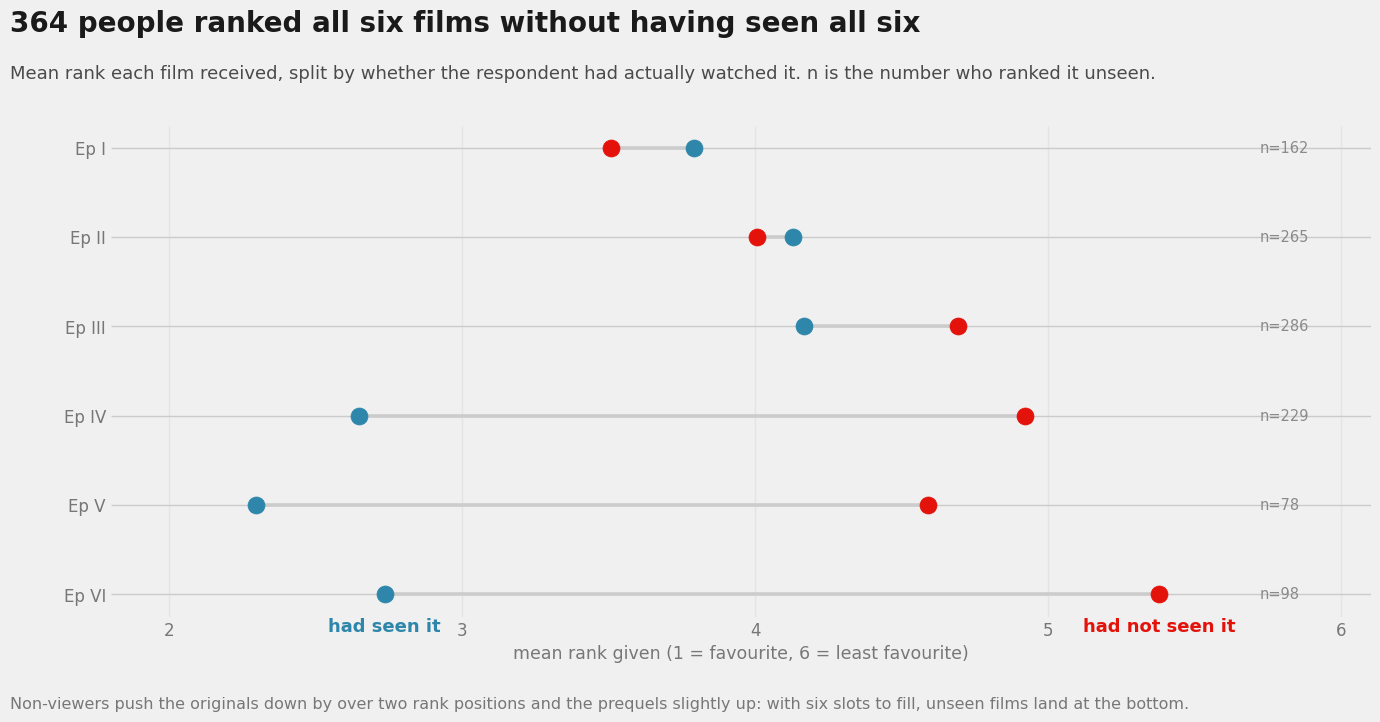

In [8]:
plt.style.use("fivethirtyeight")
C_SAW = "#2e86ab"
C_NOT = "#e3120b"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: viewers against non-viewers
y = np.arange(len(SHORT))
fig, ax = plt.subplots(figsize=(14, 7.5))
for yi, (_, r) in zip(y, gap_table.iterrows()):
    ax.plot([r["viewers"], r["nonviewers"]], [yi, yi], color="#cccccc", linewidth=2.6, zorder=3)
    ax.scatter([r["viewers"]], [yi], s=150, color=C_SAW, zorder=4)
    ax.scatter([r["nonviewers"]], [yi], s=150, color=C_NOT, zorder=5)
    ax.text(5.72, yi, "n=%d" % r["n_unseen"], va="center", fontsize=10.5, color="#8a8a8a")

ax.set_yticks(y)
ax.set_yticklabels(SHORT, fontsize=13)
ax.invert_yaxis()
ax.set_xlim(1.8, 6.1)
ax.set_xticks([2, 3, 4, 5, 6])
ax.set_xlabel("mean rank given (1 = favourite, 6 = least favourite)", fontsize=12.5, color="#777777")
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

ax.text(gap_table.iloc[5]["viewers"], 5.42, "had seen it", color=C_SAW,
        fontsize=13, weight="bold", ha="center")
ax.text(gap_table.iloc[5]["nonviewers"], 5.42, "had not seen it", color=C_NOT,
        fontsize=13, weight="bold", ha="center")

fig.subplots_adjust(left=0.085, right=0.985, top=0.800, bottom=0.145)
fig.text(0.013, 0.925, "364 people ranked all six films without having seen all six",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Mean rank each film received, split by whether the respondent had actually watched it. n is the number who ranked it unseen.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "Non-viewers push the originals down by over two rank positions and the prequels slightly up: with six slots to fill, unseen films land at the bottom.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds


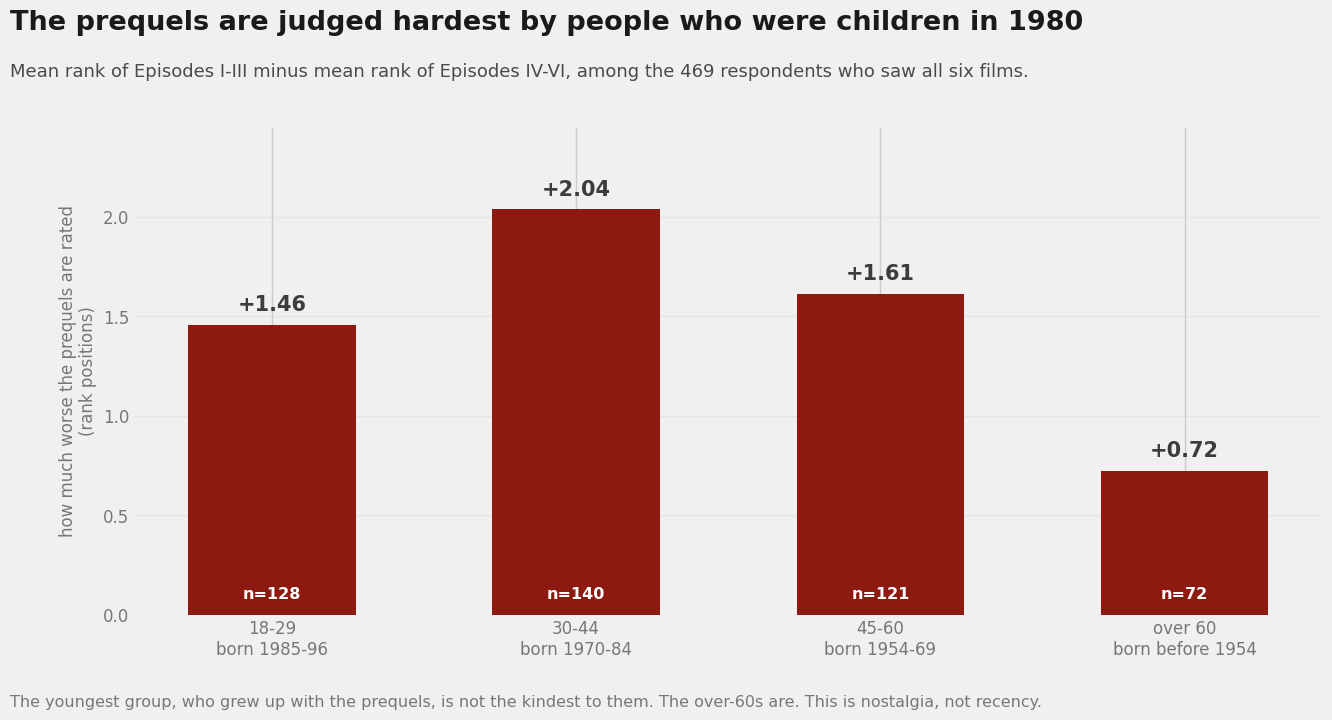

In [9]:
# Chart 2: the nostalgia curve
fig, ax = plt.subplots(figsize=(13.5, 7.5))
x = np.arange(len(age_table))
ax.bar(x, age_table["gap"], color="#8c1a10", width=0.55, zorder=3)

for xi, (g, n) in enumerate(zip(age_table["gap"], age_table["n"])):
    ax.text(xi, g + 0.07, "%+.2f" % g, ha="center", fontsize=15, weight="bold", color="#3c3c3c")
    ax.text(xi, 0.08, "n=%d" % n, ha="center", fontsize=11.5, color="white", weight="bold")

ax.set_xticks(x)
ax.set_xticklabels(["18-29\nborn 1985-96", "30-44\nborn 1970-84",
                    "45-60\nborn 1954-69", "over 60\nborn before 1954"], fontsize=12.5)
ax.set_ylim(0, 2.45)
ax.set_yticks([0, 0.5, 1.0, 1.5, 2.0])
ax.set_ylabel("how much worse the prequels are rated\n(rank positions)", fontsize=12, color="#777777")
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)

fig.subplots_adjust(left=0.105, right=0.985, top=0.795, bottom=0.145)
fig.text(0.013, 0.925, "The prequels are judged hardest by people who were children in 1980",
         fontsize=19.5, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Mean rank of Episodes I-III minus mean rank of Episodes IV-VI, among the 469 respondents who saw all six films.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "The youngest group, who grew up with the prequels, is not the kindest to them. The over-60s are. This is nostalgia, not recency.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
plt.show()

Chart 3: 3 figure texts, 0 out of bounds

all charts within bounds: True


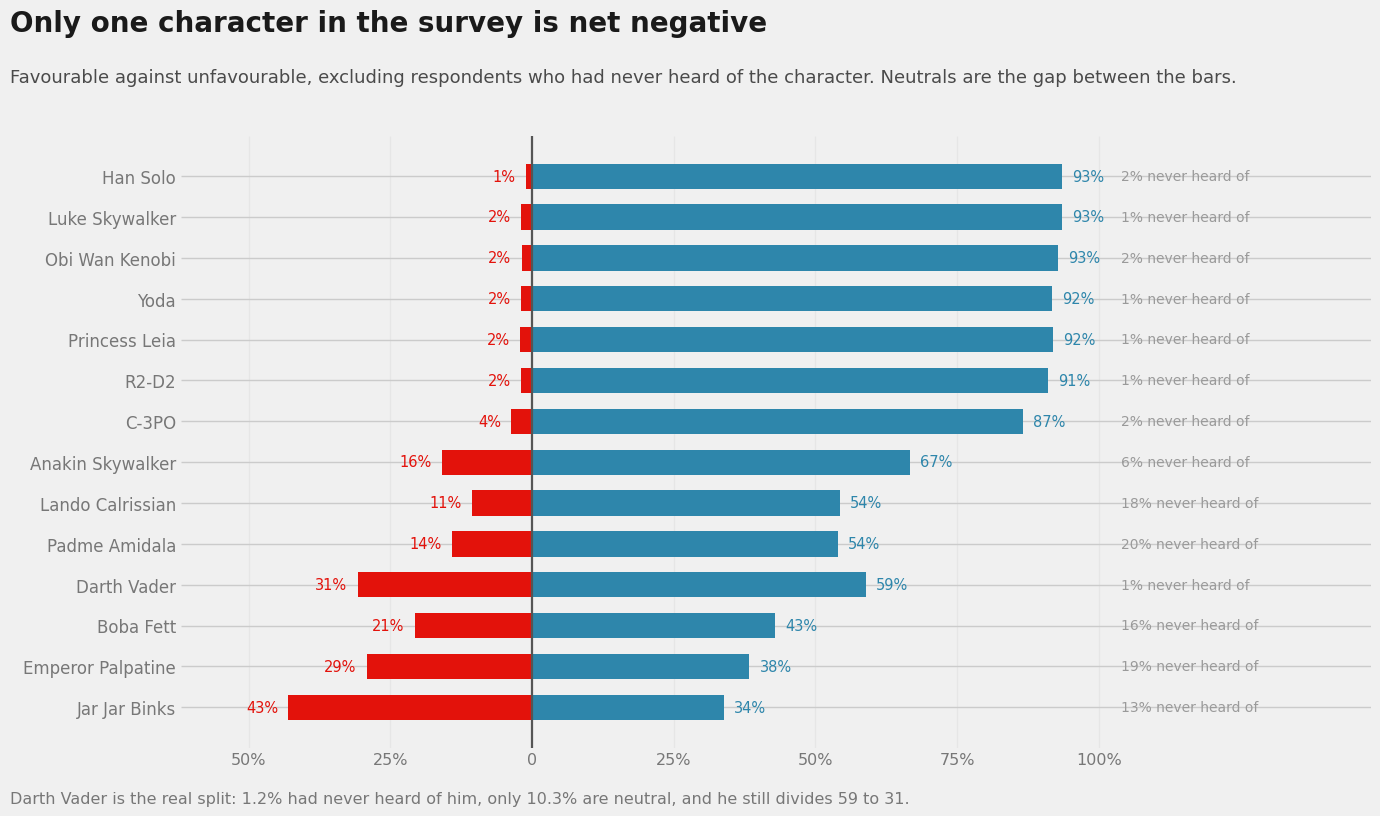

In [10]:
# Chart 3: favourability, with the unfamiliar share made visible
order = characters.sort_values("net", ascending=True).reset_index(drop=True)
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.barh(y, order["fav_pct"], color="#2e86ab", height=0.62, zorder=3, label="favourable")
ax.barh(y, -order["unfav_pct"], color="#e3120b", height=0.62, zorder=3, label="unfavourable")
ax.axvline(0, color="#555555", linewidth=1.6, zorder=4)

for yi, (_, r) in zip(y, order.iterrows()):
    ax.text(r["fav_pct"] + 1.8, yi, "%.0f%%" % r["fav_pct"], va="center", fontsize=10.5, color="#2e86ab")
    ax.text(-r["unfav_pct"] - 1.8, yi, "%.0f%%" % r["unfav_pct"], va="center",
            ha="right", fontsize=10.5, color="#e3120b")
    ax.text(104, yi, "%.0f%% never heard of" % r["unfamiliar_pct"], va="center",
            fontsize=10, color="#9a9a9a")

ax.set_yticks(y)
ax.set_yticklabels(order["character"], fontsize=12)
ax.set_xlim(-62, 148)
ax.set_xticks([-50, -25, 0, 25, 50, 75, 100])
ax.set_xticklabels(["50%", "25%", "0", "25%", "50%", "75%", "100%"], fontsize=11.5)
ax.tick_params(colors="#777777")
ax.grid(alpha=0.25, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

fig.subplots_adjust(left=0.135, right=0.985, top=0.805, bottom=0.085)
fig.text(0.013, 0.928, "Only one character in the survey is net negative",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.868,
         "Favourable against unfavourable, excluding respondents who had never heard of the character. Neutrals are the gap between the bars.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.020,
         "Darth Vader is the real split: 1.2% had never heard of him, only 10.3% are neutral, and he still divides 59 to 31.",
         fontsize=11.5, color="#777777")
ok3 = audit(fig, "Chart 3")
print()
print("all charts within bounds:", bool(ok1 and ok2 and ok3))
plt.show()

## 7. Conclusions

### The survey let people rank films they had not seen, and it changed the answer

**364 of 833 respondents who ranked all six films (43.7%) had not seen all six.** One ranked all six having seen none.

The resulting bias is large and directional. Respondents who had not seen a film rank it far worse:

| Film | Seen it | Had not | Gap |
|---|---|---|---|
| Ep VI Return of the Jedi | 2.734 | 5.378 | **+2.643** |
| Ep V Empire Strikes Back | 2.296 | 4.590 | **+2.294** |
| Ep IV A New Hope | 2.649 | 4.921 | **+2.273** |
| Ep III Revenge of the Sith | 4.164 | 4.692 | +0.528 |
| Ep II Attack of the Clones | 4.130 | 4.004 | -0.126 |
| Ep I The Phantom Menace | 3.789 | 3.506 | **-0.283** |

The mechanism is the forced-choice format: with six slots to fill, a respondent who saw only the prequels puts those at 1 to 3 and dumps the unseen originals into 4 to 6. Those ranks are not opinions about the films.

### Restricting to the 469 who saw everything reorders the list

| | Full sample | Clean sample |
|---|---|---|
| 1st | Ep V (2.510) | Ep V (2.369) |
| 2nd | Ep VI (3.044) | **Ep IV (2.861)** |
| 3rd | Ep IV (3.272) | **Ep VI (2.925)** |
| 4th | Ep I (3.734) | Ep I (4.247) |
| 5th | Ep II (4.090) | **Ep III (4.260)** |
| 6th | Ep III (4.345) | **Ep II (4.337)** |

*Empire* holds first place either way, the one robust result. **The Phantom Menace is the casualty**: a comfortable fourth at 3.734 in the full sample, it falls to 4.247 and into a three-way tie at the bottom, all three prequels separated by less than a tenth of a rank. Its apparent respectability came from people who never watched it.

### The generational prediction was backwards

| Age in 2014 | Born | Prequels judged worse by |
|---|---|---|
| 18-29 | 1985-96 | +1.46 |
| **30-44** | 1970-84 | **+2.04 (harshest)** |
| 45-60 | 1954-69 | +1.61 |
| **over 60** | before 1954 | **+0.72 (kindest)** |

The obvious hypothesis is that the youngest respondents, who grew up with the prequels, would be kindest to them, with the gap widening by age. The data says the opposite: the kindest group is the over-60s and the harshest is the 30-44 band, who were children during the original trilogy and adults when the prequels arrived.

**The effect tracks childhood attachment, not recency.** The youngest group sits in the middle; they simply dislike the prequels less than people who were ten years old in 1980.

### Characters

- **Most liked: Han Solo**, 93.5% favourable against 1.1% unfavourable (net +92.4). Luke (+91.5) and Obi-Wan (+91.0) are within two points, so this is a near-tie rather than a verdict.
- **Most disliked: Jar Jar Binks**, the only net-negative character in the survey (-9.1), at 43.0% unfavourable.
- **Most controversial** depends on how the unfamiliar responses are treated. By the raw split, Jar Jar (67.8) edges Darth Vader (61.6). But 13.3% had never heard of Jar Jar and 23.1% are neutral, while **Vader is known to 98.8% of respondents, leaves only 10.3% neutral, and still divides 59 to 31.** Vader is the character this audience has genuinely made up its mind about, in two directions.

### What I would not claim

- **This is a 2014 SurveyMonkey Audience panel,** not a probability sample of anyone. It skews toward people willing to take an internet survey about Star Wars, and FiveThirtyEight published it with that caveat.
- **Ranks are compositional.** The six mean ranks must sum to 21 by construction, so they cannot move independently and a film rising necessarily pushes others down. Treating the six columns as independent measurements would be wrong.
- **"Had not seen it" is self-reported** in a separate question, and some of the 364 may have seen a film and failed to tick it. That would make the gaps an overestimate, though not by enough to explain a 2.6-rank difference.
- **The age bands are coarse and the cohort story is an interpretation.** The data shows a non-monotonic age pattern; the nostalgia explanation fits but is not tested here, and the over-60 cell is the smallest at 72.
- **Character favourability has no error bars here.** The top six characters sit within three points of each other, which is well inside sampling noise for n around 830.
- **The controversy metric is a choice.** 2 x min(fav, unfav) is defensible but not unique, and a metric weighting *very* favourable against *very* unfavourable would rank these characters differently.

---

*Dataset: FiveThirtyEight Star Wars survey, collected June 2014 via SurveyMonkey Audience.*